
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Excelente trabalho nesta revisão! Você corrigiu todos os problemas anteriores: as distribuições agora cobrem todas as features, o random forest e o K-means são reproduzíveis, a comparação dos modelos corresponde aos seus resultados, o dendrograma foi interpretado, e os números dos clusters e as taxas de churn estão consistentes ao longo da sua análise e das conclusões. Para seu crescimento futuro, concentre-se em descrever `Partner` e `Promo_friends` com precisão, em plotar as features dos clusters de uma forma que torne cada grupo visível, e em formatar sua conclusão final para que cada recomendação seja fácil de ler. Continue com o ótimo trabalho!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram


data = pd.read_csv('/datasets/gym_churn_us.csv', sep=',')
print(data.info())
print(data.describe())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float

<div class="alert alert-block alert-success">
Bom começo. Você carregou os dados do caminho correto e os inspecionou com `info()` e `describe()`. A saída confirma 4000 linhas e nenhum valor ausente, e seus imports estão agrupados de forma organizada no topo. Como dica opcional, adicione uma frase curta após a inspeção dizendo o que você observou, como "nenhum valor ausente".
</div>

In [2]:
# Passo 2: Análise exploratória dos dados (AED)

grouped_mean = data.groupby('Churn').mean()
print(grouped_mean)

         gender  Near_Location   Partner  Promo_friends     Phone  \
Churn                                                               
0      0.510037       0.873086  0.534195       0.353522  0.903709   
1      0.510839       0.768143  0.355325       0.183789  0.902922   

       Contract_period  Group_visits        Age  Avg_additional_charges_total  \
Churn                                                                           
0             5.747193      0.464103  29.976523                    158.445715   
1             1.728558      0.268615  26.989632                    115.082899   

       Month_to_end_contract  Lifetime  Avg_class_frequency_total  \
Churn                                                               
0                   5.283089  4.711807                   2.024876   
1                   1.662582  0.990575                   1.474995   

       Avg_class_frequency_current_month  
Churn                                     
0                               2.0

Pelo que pode ser observado nos dados acima é que para Contract_period, Lifeitme, Month_to_end_contract,
Avg_class_frequency_total e _current_month a diferença entre os que continuaram matriculado (churn=0) e os que cancelaram (churn=1) é significativa, ou seja, a diferença é perceptível. A conclusão sugere que contratos mais longos e maior engajamento(frequência as aulas) estão associados a menor chance de cancelamento.

<div class="alert alert-block alert-warning">
Sua leitura da tabela de médias está no caminho certo: contratos mais longos e maior engajamento estão associados a uma menor chance de saída. Alguns refinamentos opcionais: (1) A tabela mostra outras diferenças claras também, como `Age` (cerca de 30 vs 27), `Avg_additional_charges_total` (cerca de 158 vs 115), `Partner` (0,53 vs 0,36), `Promo_friends` (0,35 vs 0,18) e `Group_visits` (0,46 vs 0,27), enquanto `gender` e `Phone` são praticamente idênticos. (2) "Significativa" sugere um teste estatístico, que você não executou. "Notável" ou "acentuada" é mais preciso, e um número concreto, como `Contract_period` ≈ 5,7 vs 1,7 meses, reforçaria a afirmação. (3) Erros de digitação: "Lifeitme" deveria ser "Lifetime" e "frequência as aulas" deveria ser "frequência às aulas".
</div>

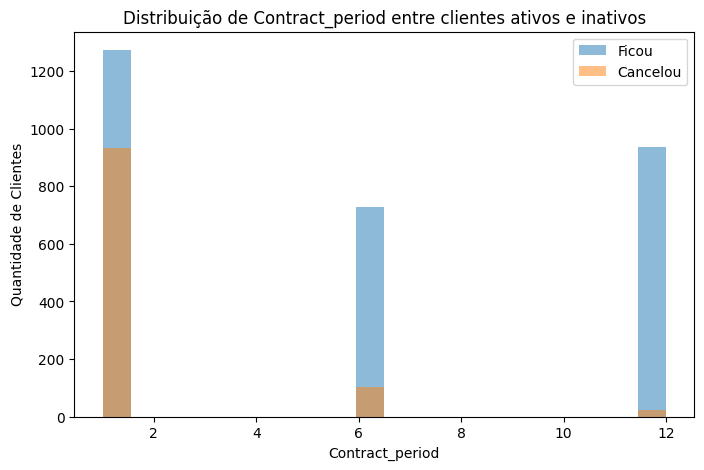

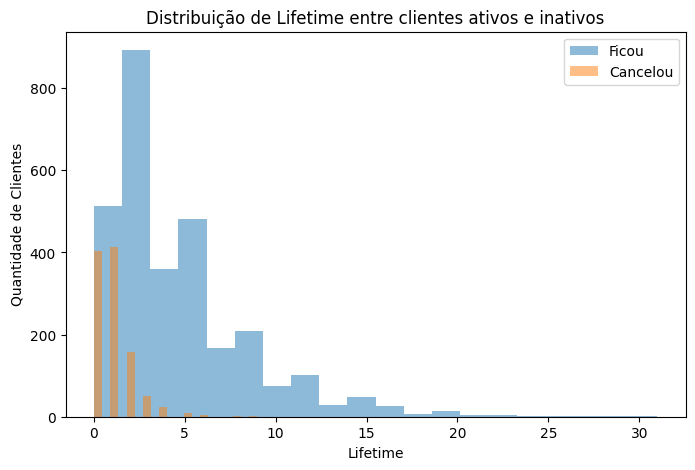

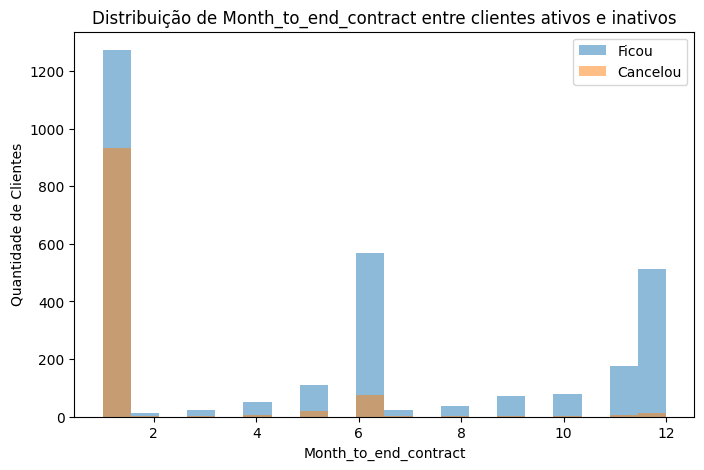

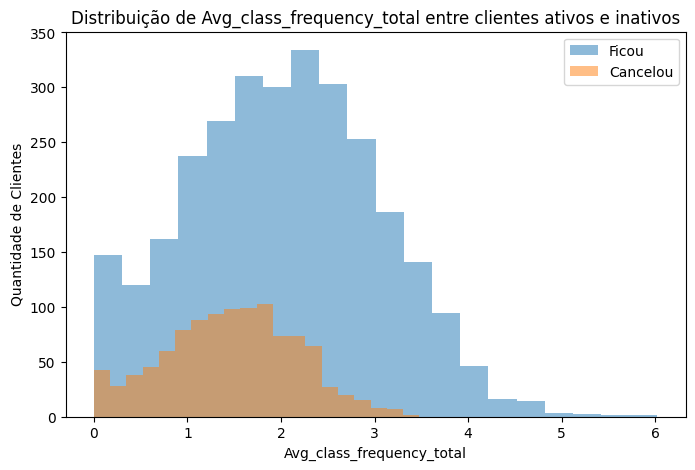

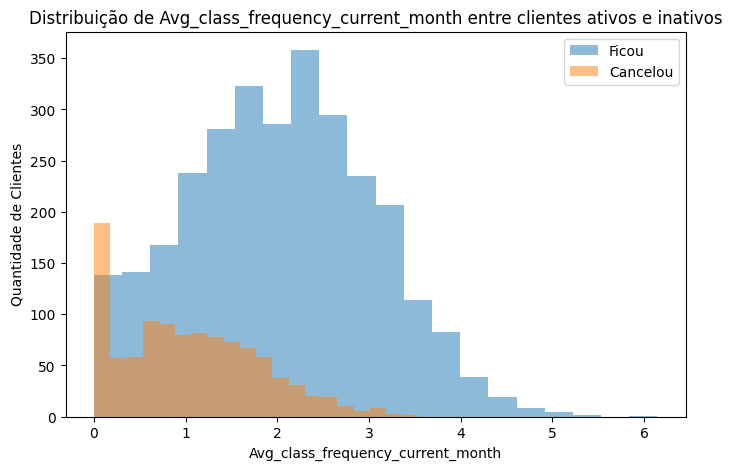

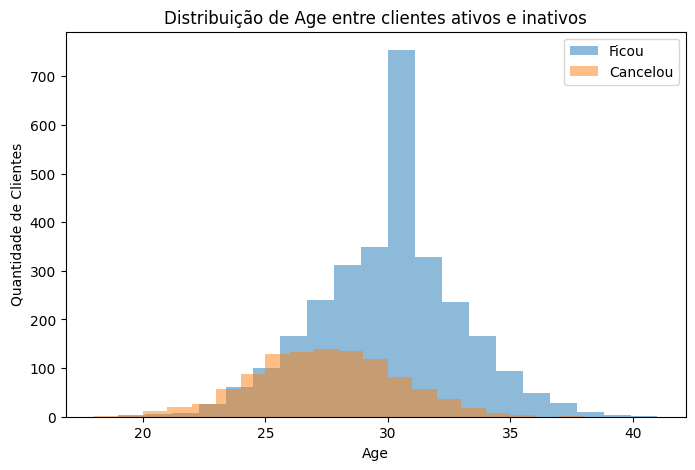

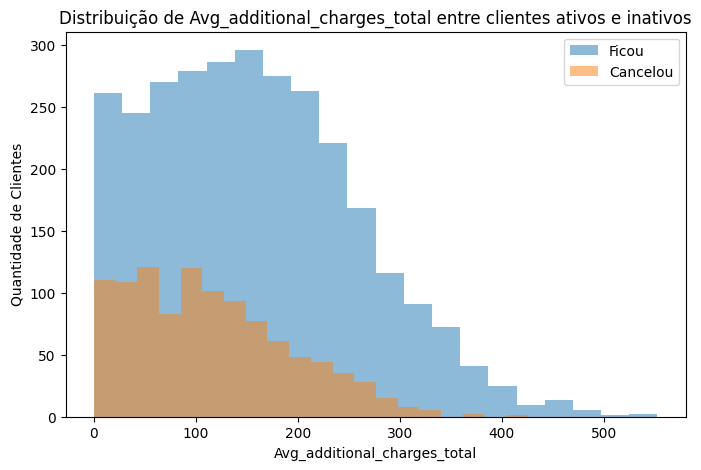

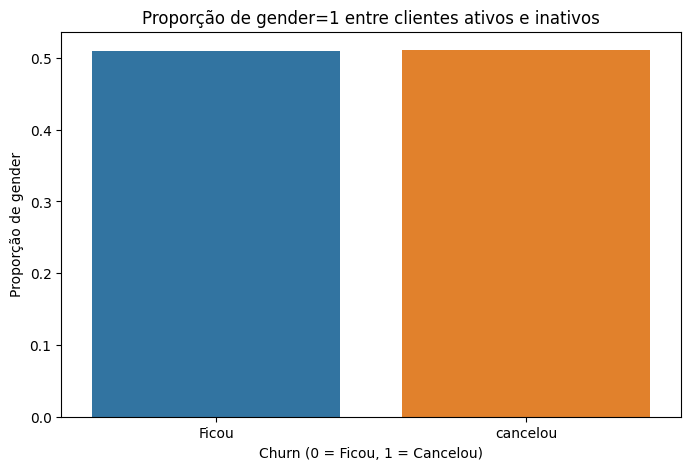

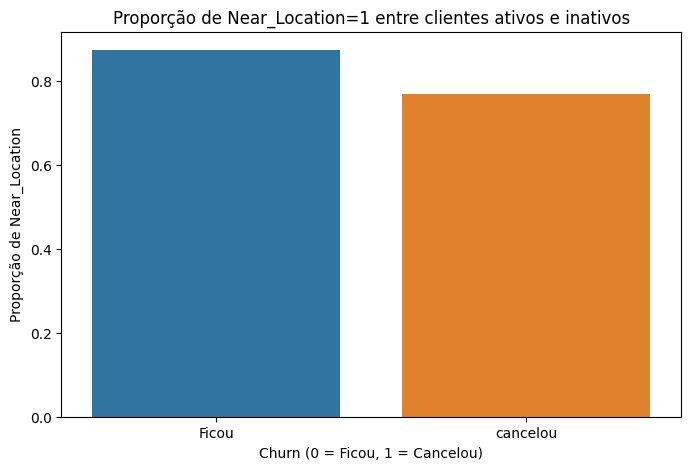

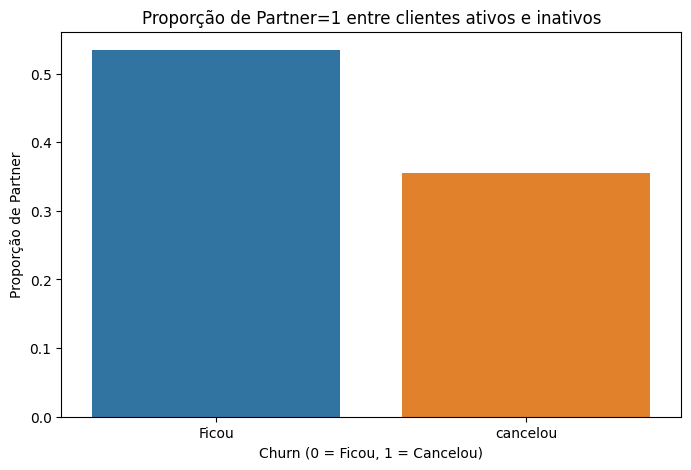

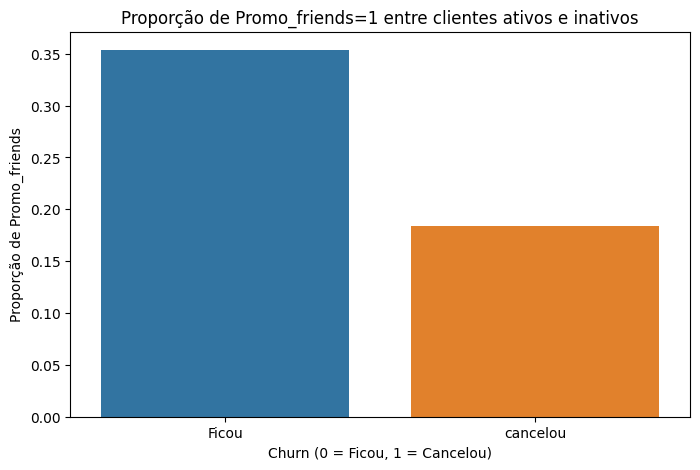

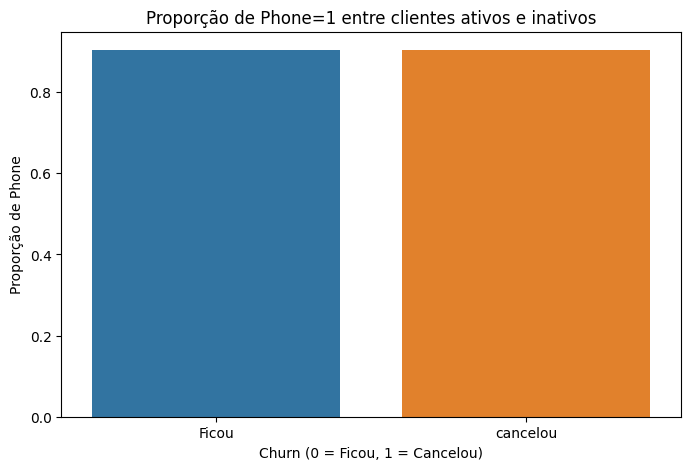

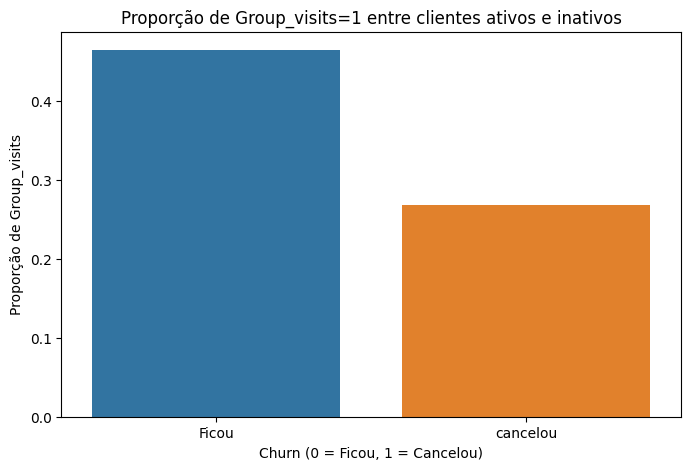

In [3]:
# 1. Lista de variáveis numéricas/contínuas
numerical_features = [
    'Contract_period', 
    'Lifetime', 
    'Month_to_end_contract', 
    'Avg_class_frequency_total', 
    'Avg_class_frequency_current_month',
    'Age', 
    'Avg_additional_charges_total'
]

# 2. Lista de variáveis binárias (0 ou 1)
binary_features = [
    'gender', 
    'Near_Location', 
    'Partner', 
    'Promo_friends', 
    'Phone', 
    'Group_visits'
]


for feature in numerical_features:
    plt.figure(figsize=(8, 5))
    
    plt.hist(data[data['Churn'] == 0][feature], bins=20, alpha=0.5, label='Ficou')
    plt.hist(data[data['Churn'] == 1][feature], bins=20, alpha=0.5, label='Cancelou')
    
    plt.legend()
    plt.title(f'Distribuição de {feature} entre clientes ativos e inativos')
    plt.xlabel(feature)
    plt.ylabel('Quantidade de Clientes')
    plt.show()


for feature in binary_features:
    plt.figure(figsize=(8, 5))
    
    # A média da coluna binária representa a proporção de 1s para cada grupo de Churn
    prop_data = data.groupby('Churn')[feature].mean().reset_index()
    
    # Plotagem simples da proporção por grupo
    sns.barplot(x='Churn', y=feature, data=prop_data)
    
    plt.title(f'Proporção de {feature}=1 entre clientes ativos e inativos')
    plt.xlabel('Churn (0 = Ficou, 1 = Cancelou)')
    plt.ylabel(f'Proporção de {feature}')
    plt.xticks([0, 1], ['Ficou', 'cancelou'])
    plt.show()
    

<div class="alert alert-block alert-warning">
Ótimo trabalho ao estender a comparação para todas as 13 features. Duas listas (numéricas e binárias) e dois loops mostram que você não repetiu código, e cada tipo de variável recebe um gráfico adequado. Os gráficos de barras estão de acordo com a sua tabela de médias, então isso fecha a principal lacuna da revisão anterior. Refinamentos opcionais: (1) Os dois grupos têm tamanhos muito diferentes, então as contagens absolutas fazem o grupo que cancelou parecer pequeno em todos os gráficos. Adicionar `density=True` ao `plt.hist` permitiria comparar os formatos das distribuições de forma justa. (2) `Contract_period` e `Month_to_end_contract` assumem apenas poucos valores, então 20 bins deixam lacunas e barras finas. Usar menos bins ou um count plot funcionaria melhor. (3) O rótulo do x-tick `'cancelou'` está em minúsculas enquanto `'Ficou'` está com inicial maiúscula, então colocar ambos com inicial maiúscula deixaria tudo mais organizado.
</div>


A análise integrada de todas as distribuições revela que os clientes que cancelaram o serviço (Churn = 1) apresentam um perfil bem definido: possuem contratos curtos, tempo de casa (Lifetime) inferior a dois meses, idades ligeiramente menores, menores gastos adicionais e uma queda acentuada na frequência semanal de treinos no mês corrente. Além disso, a comparação das proporções mostra que a evasão é significativamente maior entre alunos que não frequentam aulas em grupo (Group_visits), não vieram indicados por parceiros corporativos (Partner) ou por amigos (Promo_friends), enquanto variáveis como gênero (gender) e cadastro de telefone (Phone) mantêm-se praticamente idênticas entre os dois grupos. Em suma, o churn é impulsionado por um baixo engajamento inicial e pela falta de vínculos sociais e contratuais de longo prazo com a academia.

<div class="alert alert-block alert-warning">
Sua leitura escrita agora cobre todas as variáveis e traça um perfil claro do cliente que cancela, o que é uma boa melhoria. Há duas coisas a corrigir: (1) `Partner` não significa ter sido indicado por uma empresa parceira. Ele marca os clientes que trabalham em uma empresa parceira que oferece desconto. `Promo_friends` é a inscrição do tipo "traga um amigo". Por favor, descreva cada uma com precisão, já que suas recomendações dependem de ambas. (2) `Near_Location` está faltando no seu perfil. Seu gráfico e sua tabela mostram que ela é menor entre os clientes que cancelam (cerca de 0,77 contra 0,87), e sua conclusão final depende da distância. Além disso, "significativamente maior" sugere um teste estatístico. "Visivelmente maior" corresponde ao que os gráficos mostram.
</div>

In [4]:
# Contruindo a matriz de correlação 

corr_matrix = data.corr()
print(corr_matrix)

                                     gender  Near_Location   Partner  \
gender                             1.000000       0.006699 -0.010463   
Near_Location                      0.006699       1.000000 -0.005119   
Partner                           -0.010463      -0.005119  1.000000   
Promo_friends                     -0.005033       0.210964  0.451960   
Phone                             -0.008542      -0.015763  0.009970   
Contract_period                    0.000502       0.150233  0.306166   
Group_visits                       0.017879       0.154728  0.022710   
Age                                0.013807       0.058358  0.047480   
Avg_additional_charges_total      -0.009334       0.040761  0.022941   
Month_to_end_contract             -0.001281       0.143961  0.294632   
Lifetime                           0.013579       0.070921  0.061229   
Avg_class_frequency_total          0.014620       0.043127  0.024938   
Avg_class_frequency_current_month  0.009156       0.062664  0.04

Pelo que se pode ser observado na matriz de correlação acima, há uma forte correlação entre Contract_period e Month_to_end_contract (0.973064), ou seja, a duração dos contratos está diretamente ligada com a coluna que mostra quantos meses faltam para o contrato acabar. O mesmo acontece com Avg_class_frequency_total e Avg_class_frequency_current_month (0.952739) que é a relação entre a frequência média de aulas desde que a pessoa começou na academia e a frequência média só no mês mais recente. A correlação alta entre essas duas variáveis mostra que o comportamento de frequência de cada pessoa é consistente ao longo do tempo (quem é ativo no geral continua ativo agora, quem é pouco ativo continua pouco ativo). Essas consistências de comportamento é compatível com o que mostra o histograma:  quem cancela tende a ter frequência baixa tanto no histórico quanto no mês atual e quem fica tende a manter frequência mais alta nos dois casos.

<AxesSubplot:title={'center':'Gráfico Heatmap entre as Features e Churn'}>

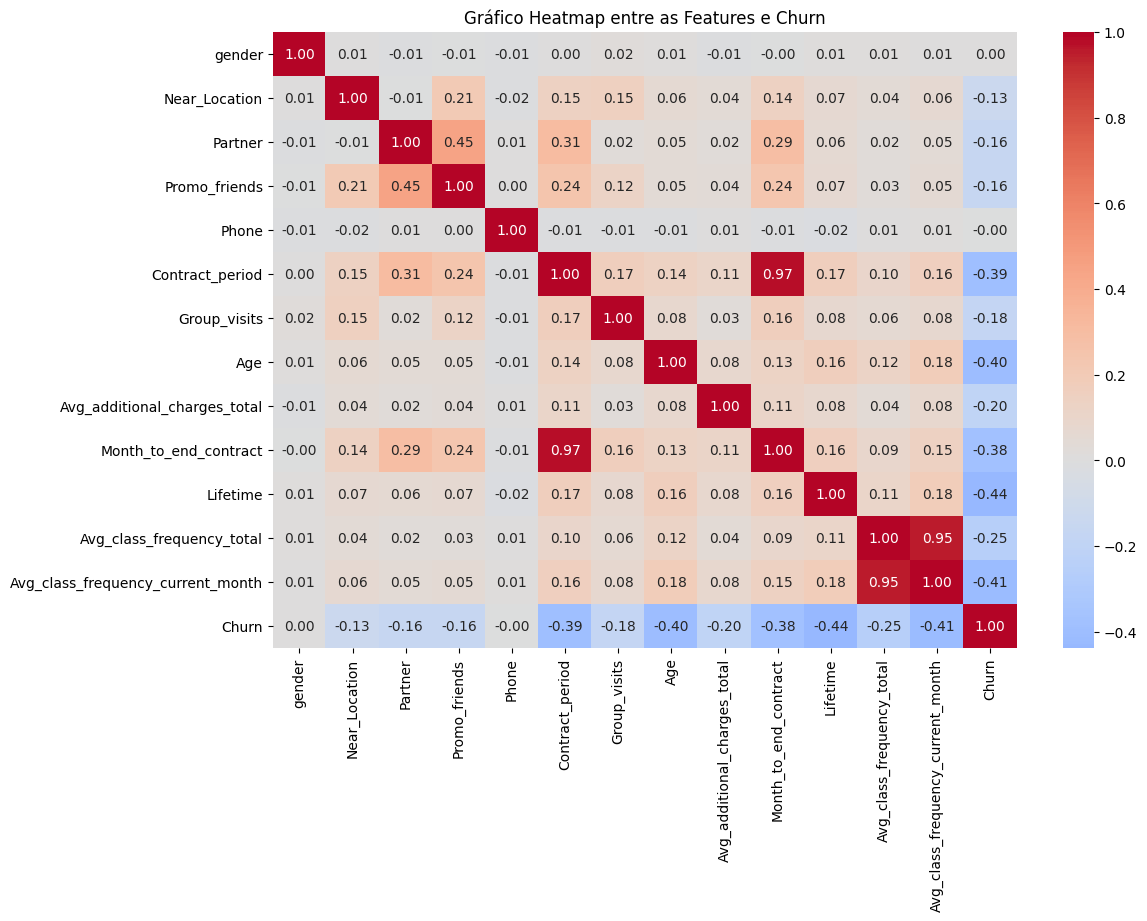

In [5]:
# Vamos criar um heatmap 

plt.figure(figsize=(12, 8))
plt.title('Gráfico Heatmap entre as Features e Churn')

sns.heatmap(corr_matrix, annot = True, fmt = '.2f', cmap='coolwarm', center=0)

Pelo que se pode observar no heatmap, Lifetime e Avg_class_frequency_current_month são as correlações mais fortes com a coluna Churn, o que nos mostra que os clientes que cancelaram tendem a ter Lifetime mais baixo (desistem mais facilmente) e a frequência das aulas mais baixa no mês atual.

<div class="alert alert-block alert-warning">
Sua conclusão está correta: `Lifetime` (cerca de -0,44) e `Avg_class_frequency_current_month` (cerca de -0,41) têm as correlações mais fortes com `Churn`. O mapa de calor (heatmap) também melhorou bastante, com um título e um mapa de cores `coolwarm` centralizado em zero. Como um complemento opcional, `Age` (-0,40), `Contract_period` (-0,39) e `Month_to_end_contract` (-0,38) são quase tão fortes, e mencioná-las completaria o quadro e o conectaria ao perfil que você descreveu após os gráficos de distribuição.
</div>

In [6]:
# Passo 3: construir um modelo de classificação binária

X = data.drop(columns='Churn')
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 1)

model_lr = LogisticRegression(max_iter = 1000, random_state = 1)
model_lr.fit(X_train, y_train)
predictions_lr = model_lr.predict(X_test)

accuracy = accuracy_score(y_test, predictions_lr)
precision = precision_score(y_test, predictions_lr)
recall = recall_score(y_test, predictions_lr)

print('Acurácia:', round(accuracy, 2))
print('Precisão:', round(precision, 2))
print('Recall:', round(recall, 2))


Acurácia: 0.93
Precisão: 0.89
Recall: 0.86


In [7]:

# contruir o modelo para a floresta aleatória

model_rf = RandomForestClassifier(random_state=1)
model_rf.fit(X_train, y_train)
predictions_rf = model_rf.predict(X_test)

accuracy = accuracy_score(y_test, predictions_rf)
precision = precision_score(y_test, predictions_rf)
recall = recall_score(y_test, predictions_rf)

print('Acurácia:', round(accuracy, 2))
print('Precisão:', round(precision, 2))
print('Recall:', round(recall, 2))

    

Acurácia: 0.93
Precisão: 0.89
Recall: 0.84


<div class="alert alert-block alert-success">
Você resolveu o problema de reprodutibilidade definindo `random_state=1` no random forest, então as métricas (0,93 / 0,89 / 0,84) permanecem as mesmas a cada execução. Você também reutilizou a mesma divisão de treino/teste, de modo que os dois modelos são comparados nos mesmos dados, e cada modelo tem seus próprios nomes de variáveis. Dica opcional: imprima as métricas dos dois modelos em uma pequena tabela para facilitar a comparação.
</div>

Ambos os modelos apresentaram desempenho muito próximo no conjunto de teste, com acurácia de 0.93 e precisão de 0.89. A pequena diferença no Recall (0.86 na Regressão Logística contra 0.84 na Floresta Aleatória) está dentro da margem de variação natural das amostras. Ainda assim, recomenda-se a utilização da Regressão Logística para a academia. Como a performance de ambos é equivalente, a Regressão Logística oferece a vantagem de ser um modelo mais simples e altamente interpretável, permitindo analisar diretamente os coeficientes para entender quais fatores aumentam ou reduzem o risco de churn.

<div class="alert alert-block alert-success">
Sua comparação agora está de acordo com os seus resultados: acurácia de 0,93 e precisão de 0,89 para ambos, recall de 0,86 vs 0,84. Você trata os modelos como praticamente empatados e justifica a escolha da regressão logística pela simplicidade e pela interpretabilidade por meio dos coeficientes, o que é um argumento sólido. Um pequeno ponto opcional: a afirmação "dentro da variação natural das amostras" não foi testada, então você poderia suavizá-la ou embasá-la com validação cruzada ou com algumas seeds diferentes.
</div>

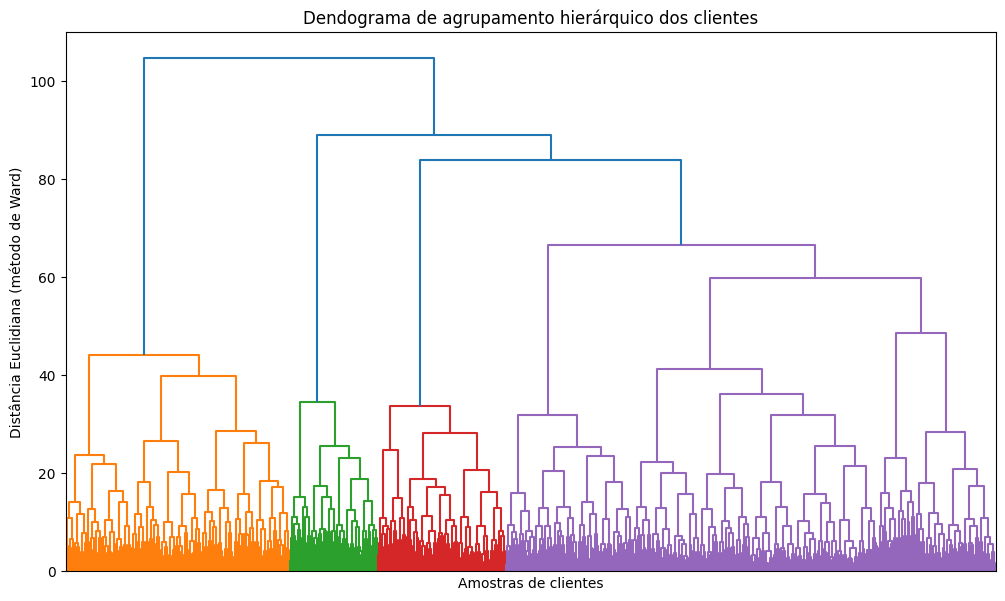

In [8]:
# Passo 4: Criar agrupamentos de clientes

scaler = StandardScaler()
X_sc = scaler.fit_transform(X)

matrix = linkage(X_sc, method='ward')
plt.figure(figsize=(12, 7))
dendrogram(matrix, no_labels = True)
plt.title('Dendograma de agrupamento hierárquico dos clientes')
plt.xlabel('Amostras de clientes')
plt.ylabel('Distância Euclidiana (método de Ward)')
plt.show()




<div class="alert alert-block alert-success">
Muito bem. As features estão padronizadas, `Churn` ficou de fora e você usou `linkage` com o método de Ward. O gráfico agora tem título, rótulos nos eixos e `no_labels=True`, então está muito mais fácil de ler do que antes. Pequeno erro de digitação: "Dendograma" deveria ser "Dendrograma".
</div>

O gráfico do dendrograma indica que os clientes se dividem naturalmente em 4 grupos principais. Porém, o projeto orienta usar 5 grupos no algoritmo K-Means. Essa divisão em 5 partes é vantajosa porque pega o maior grupo de clientes (o roxo) e o divide em dois, permitindo enxergar com mais detalhes o comportamento de quem tem risco médio e alto de cancelar a academia.

<div class="alert alert-block alert-warning">
Agora você usa o dendrograma para estimar o número de clusters. Sua leitura de quatro grupos principais condiz com o gráfico, e você explica corretamente que o quinto cluster do K-Means vem da divisão do ramo roxo grande. Dois refinamentos opcionais: (1) Diga onde você cortaria a árvore, por exemplo, a altura aproximada no eixo y (em torno de 70) que resulta em 4 grupos. (2) Formule o benefício de ver "risco médio e alto" como uma expectativa, porque nada neste ponto mostra isso ainda.
</div>

In [9]:
model_km = KMeans(n_clusters=5, random_state = 1)
data['cluster'] = model_km.fit_predict(X_sc)
data.head()

grouped_cluster = data.groupby('cluster')['Churn'].mean()
cluster_means = data.groupby('cluster').mean()
print(f"Taxa de Churn por Cluster:\n{grouped_cluster}")
print(cluster_means)



Taxa de Churn por Cluster:
cluster
0    0.429942
1    0.362148
2    0.019544
3    0.252713
4    0.266839
Name: Churn, dtype: float64
           gender  Near_Location   Partner  Promo_friends  Phone  \
cluster                                                            
0        0.500960       0.000000  0.464491       0.078695    1.0   
1        0.519319       1.000000  0.224623       0.000000    1.0   
2        0.498371       0.951140  0.739414       0.466884    1.0   
3        0.505426       1.000000  0.773643       1.000000    1.0   
4        0.523316       0.862694  0.471503       0.305699    0.0   

         Contract_period  Group_visits        Age  \
cluster                                             
0               2.343570      0.216891  28.579655   
1               2.056974      0.379175  28.918140   
2              11.511401      0.543974  29.964169   
3               2.972093      0.451163  29.120930   
4               4.777202      0.427461  29.297927   

         Avg_addit

<div class="alert alert-block alert-success">
Você corrigiu os problemas da última rodada. `random_state=1` torna os rótulos dos clusters estáveis entre as execuções, a taxa de churn por cluster é exibida ao lado da tabela de médias, e o K-means roda sobre as variáveis padronizadas, sem `Churn`. Isso facilita a conferência das porcentagens que você cita mais adiante. Dois pequenos ajustes: `data.head()` no meio da célula não exibe nada, então remova-o ou mova-o para o final, e um nome como `churn_by_cluster` seria mais adequado para `grouped_cluster`.
</div>

A segmentação em 5 grupos mostra claramente o que segura ou afasta os alunos: o Cluster 2 é o mais fiel (1,95% de churn) por reunir contratos longos de 12 meses, alta frequência de treinos e vínculo com empresas parceiras; os Clusters 3 (25,27% de churn) e 4 (26,68%) apresentam risco moderado, destacando-se, respectivamente, por 100% de indicações de amigos e pela ausência total de telefone cadastrado; já os Clusters 1 (36,21%) e 0 (42,99%) concentram o maior risco de cancelamento devido a contratos muito curtos (cerca de 2 meses) e, no caso do Cluster 0, pelo fato de os clientes morarem longe da academia e treinarem com menor frequência.

<div class="alert alert-block alert-warning">
As descrições dos seus clusters agora correspondem à tabela: números dos clusters, taxas de churn, duração dos contratos, `Near_Location`, `Promo_friends` e `Phone`. Este era o principal ponto a corrigir, e ficou bem feito. Dois refinamentos: (1) `Phone` foi praticamente idêntico entre os clientes que ficaram e os que saíram (cerca de 0,90 nos dois grupos), e o churn do Cluster 4 (26,7%) é próximo ao do Cluster 3 (25,3%). Apresente a ausência de número de telefone como uma característica definidora desse grupo, e não como a razão do seu churn. (2) Você diz que o Cluster 2 tem "alta frequência" e que o Cluster 0 treina "com menor frequência". Fundamente essa afirmação com as médias reais de `Avg_class_frequency_current_month` por cluster, por exemplo imprimindo apenas essas colunas.
</div>

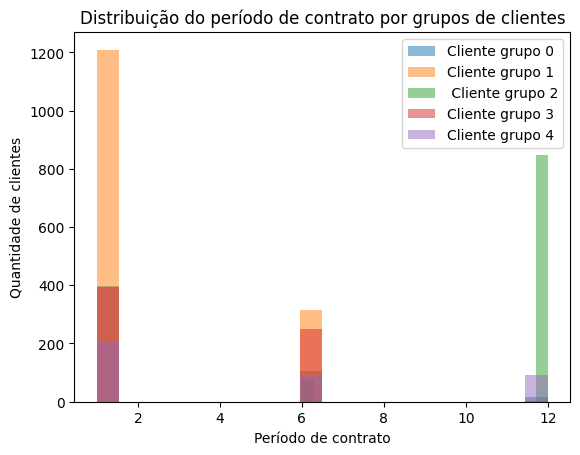

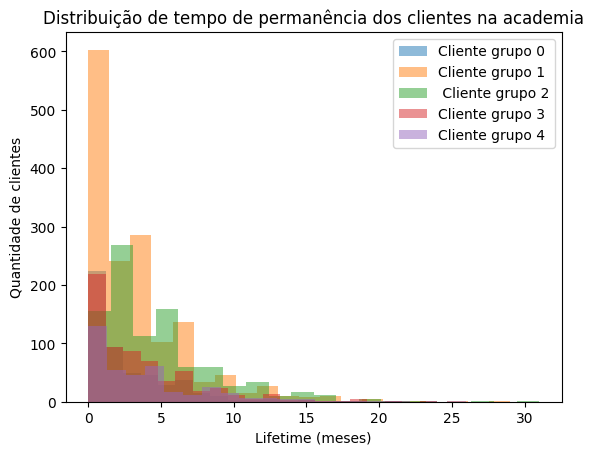

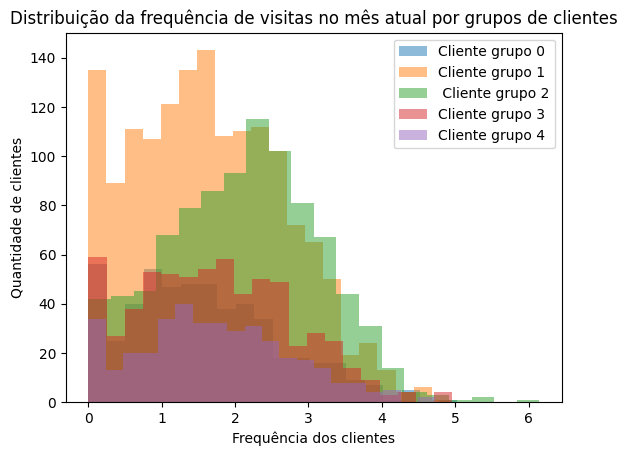

In [10]:
# Histograma para os cluters

plt.hist(data[data['cluster'] == 0]['Contract_period'], bins = 20, alpha = 0.5, label = 'Cliente grupo 0')

plt.hist(data[data['cluster'] == 1]['Contract_period'], bins = 20, alpha = 0.5, label = 'Cliente grupo 1')

plt.hist(data[data['cluster']== 2]['Contract_period'], bins = 20, alpha = 0.5, label = ' Cliente grupo 2')

plt.hist(data[data['cluster'] == 3]['Contract_period'], bins = 20, alpha = 0.5, label = 'Cliente grupo 3')

plt.hist(data[data['cluster'] == 4]['Contract_period'], bins = 20, alpha = 0.5, label = 'Cliente grupo 4')

plt.legend()
plt.title('Distribuição do período de contrato por grupos de clientes')
plt.xlabel('Período de contrato')
plt.ylabel('Quantidade de clientes')
plt.show()



plt.hist(data[data['cluster'] == 0]['Lifetime'], bins = 20, alpha = 0.5, label = 'Cliente grupo 0')

plt.hist(data[data['cluster'] == 1]['Lifetime'], bins = 20, alpha = 0.5, label = 'Cliente grupo 1')

plt.hist(data[data['cluster']== 2]['Lifetime'], bins = 20, alpha = 0.5, label = ' Cliente grupo 2')

plt.hist(data[data['cluster'] == 3]['Lifetime'], bins = 20, alpha = 0.5, label = 'Cliente grupo 3')

plt.hist(data[data['cluster'] == 4]['Lifetime'], bins = 20, alpha = 0.5, label = 'Cliente grupo 4')

plt.legend()
plt.title('Distribuição de tempo de permanência dos clientes na academia')
plt.xlabel('Lifetime (meses)')
plt.ylabel('Quantidade de clientes')
plt.show()

plt.hist(data[data['cluster'] == 0]['Avg_class_frequency_current_month'], bins = 20, alpha = 0.5, label = 'Cliente grupo 0')

plt.hist(data[data['cluster'] == 1]['Avg_class_frequency_current_month'], bins = 20, alpha = 0.5, label = 'Cliente grupo 1')

plt.hist(data[data['cluster']== 2]['Avg_class_frequency_current_month'], bins = 20, alpha = 0.5, label = ' Cliente grupo 2')

plt.hist(data[data['cluster'] == 3]['Avg_class_frequency_current_month'], bins = 20, alpha = 0.5, label = 'Cliente grupo 3')

plt.hist(data[data['cluster'] == 4]['Avg_class_frequency_current_month'], bins = 20, alpha = 0.5, label = 'Cliente grupo 4')

plt.legend()
plt.title('Distribuição da frequência de visitas no mês atual por grupos de clientes')
plt.xlabel('Frequência dos clientes')
plt.ylabel('Quantidade de clientes')
plt.show()

<div class="alert alert-block alert-warning">
Você plotou features sensatas por cluster, e os títulos, rótulos e legendas estão claros. Sugestões: (1) Com cinco histogramas semitransparentes sobrepostos, o Cluster 0 fica quase invisível nos três gráficos, e ele é o seu grupo com maior churn. Use um subplot por cluster ou `density=True`. (2) Adicione uma breve nota sobre o que você observa, por exemplo, o Cluster 2 está concentrado em contratos de 12 meses e o Cluster 1 está concentrado em 1 mês e com `Lifetime` próximo de 0, e relacione isso às taxas de churn. (3) As features que realmente separam os seus clusters (`Near_Location`, `Phone`, `Promo_friends`, `Partner`) não foram plotadas. Gráficos de barras com as proporções delas por cluster ajudariam, e um loop sobre uma lista de features, como você fez na EDA, evita repetir o mesmo bloco de código. (4) Erro de digitação: "cluters" no comentário do topo.
</div>

Passo 5: Conclusão
A análise dos dados demonstra que o cancelamento de alunos (churn) na academia é fortemente alavancado pela curta duração dos contratos (1 a 3 meses), distância física da unidade e queda de assiduidade recente.A segmentação por clustering (K=5) fundamentou estes achados ao identificar perfis bem definidos: o Cluster 2 provou ser o mais retido (1,95% de churn) devido aos contratos de 12 meses e alto engajamento; o Cluster 4 (26,68% de churn) expôs a falta de telefone cadastrado como ponto cego de comunicação; enquanto os Clusters 1 (36,21%) e 0 (42,99%) representam os maiores riscos, impulsionados por contratos muito curtos e localização distante, respetivamente.O modelo de Regressão Logística consolidou-se como a melhor ferramenta preditiva para implementação diária, permitindo identificar precocemente alunos em risco com elevada precisão e simplicidade técnica.Recomendações Práticas de Negócio:Captação de Contactos e Onboarding: Tornar obrigatório o preenchimento de telefone no momento da adesão para resolver a lacuna identificada no Cluster 4 e permitir ações diretas de reengajamento via WhatsApp/SMS.Incentivo à Migração de Planos: Criar campanhas de conversão para planos anuais voltadas para os Clusters 1 e 3 nos primeiros 60 dias de matrícula, utilizando descontos progressivos para contornar a fragilidade dos contratos de 1 a 3 meses.Programas Sociais e Proximidade: Intensificar os incentivos de indicação de amigos (Promo_friends) e parcerias corporativas (Partner) para engajar alunos distantes ou sem vínculos sociais (como o Cluster 0), promovendo também o acompanhamento ativo quando a frequência semanal cair abaixo de 2 treinos.

<div class="alert alert-block alert-warning">
Você corrigiu o principal problema da revisão anterior. Os números dos clusters e as taxas de churn na sua conclusão agora coincidem com a sua tabela de clusters, e as suas recomendações são concretas e ligadas a clusters específicos: planos anuais nos primeiros 60 dias, descontos progressivos e monitoramento de frequência. Melhorias opcionais: (1) Os dados não mostram que a ausência de número de telefone causa churn, já que o churn do Cluster 4 está próximo da média e `Phone` é praticamente idêntico entre quem permanece e quem sai. Exigir o número de telefone ainda pode ajudar na comunicação, então apresente isso como uma medida de qualidade de contato e não como uma solução para um grupo de alto risco. (2) Você direciona os Clusters 1 e 3 para a campanha de planos anuais, mas o Cluster 0 tem o maior churn e contratos curtos (cerca de 2,3 meses). Considere incluí-lo e explique por que o Cluster 3, cujo churn está apenas ligeiramente acima da média, é uma prioridade. (3) `Lifetime` foi uma das correlações mais fortes com o churn no seu heatmap, mas está ausente da sua lista de fatores principais. Adicioná-lo reforçaria a ideia dos "primeiros 60 dias". (4) Os dois modelos ficaram quase empatados, então "consolidou-se como a melhor ferramenta" é mais forte do que a evidência permite. "Performance equivalente, com vantagem de interpretabilidade" corresponde à sua própria comparação. (5) O texto aparece todo emendado, sem espaços após vários pontos finais (por exemplo, "recente.A segmentação", "respetivamente.O modelo", "Negócio:Captação"). Adicione quebras de linha e coloque cada uma das três recomendações em seu próprio marcador (bullet), com títulos curtos em negrito.
</div>